# Transformers


#### A Transformer is a deep learning architecture designed to process sequences of text using self-attention.

- Transformers are the foundation of many modern NLP models, including BERT, GPT, and T5.

- Before Transformers, we used models such as RNNs and LSTMs for NLP tasks.

<img src="https://drive.google.com/thumbnail?id=1unPqGaKftHxp37-F99Bg6hJzFbQdCGC7&sz=w1000" width="700">

In [1]:
%pip -q install transformers torch matplotlib

## 1. Load a Transformer

We use **DistilBERT**, a  Transformer fine-tuned for positive/negative sentiment classification.

In [2]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval()

# Look inside the Transformer architecture.
print("Transformer layers:", model.config.n_layers)
print("Attention heads per layer:", model.config.n_heads)
print("Hidden size:", model.config.dim)

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Transformer layers: 6
Attention heads per layer: 12
Hidden size: 768



<img src="https://drive.google.com/thumbnail?id=1v2dRK1KR_ydZOknjj8Xv8_wjOdXleDYs&sz=w1000" width="500">

## 2. Tokenizing the text

In [3]:
sentence = "The movie was not good."

# Tokenization: converts text into token IDs
inputs = tokenizer(sentence, return_tensors="pt")

# [CLS] = start token, [SEP] = end token
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Tokens:", tokens)

Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']


## 3. Embeddings and self-attention

Each token ID becomes a **vector (embedding)**. Inside each Transformer layer, **self-attention** lets a token use information from other tokens in the same sentence.

In [4]:
import torch

# Enable attention weights
model.set_attn_implementation("eager")

with torch.no_grad():
    embeddings = model.distilbert.embeddings(inputs["input_ids"])
    outputs = model(**inputs, output_attentions=True)

# Attention from the first layer and first head
attention = outputs.attentions[0][0, 0]

print("Embeddings shape:", embeddings.shape)
print("Attention shape:", attention.shape)
print("Tokens:", tokens)
print("Attention weights:\n", attention)

Embeddings shape: torch.Size([1, 8, 768])
Attention shape: torch.Size([8, 8])
Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']
Attention weights:
 tensor([[0.1145, 0.0938, 0.0681, 0.0701, 0.0596, 0.0800, 0.1593, 0.3546],
        [0.4147, 0.0793, 0.0481, 0.1018, 0.1084, 0.0805, 0.0789, 0.0883],
        [0.1634, 0.0327, 0.0975, 0.0403, 0.1819, 0.1402, 0.0866, 0.2574],
        [0.2882, 0.1014, 0.0504, 0.0669, 0.2180, 0.1009, 0.1231, 0.0511],
        [0.3612, 0.0501, 0.0696, 0.1200, 0.0642, 0.1304, 0.0953, 0.1092],
        [0.3065, 0.0469, 0.1175, 0.1915, 0.0630, 0.0555, 0.1120, 0.1071],
        [0.3505, 0.0935, 0.0572, 0.0753, 0.0972, 0.0964, 0.1165, 0.1135],
        [0.3513, 0.1019, 0.0318, 0.0541, 0.1036, 0.0607, 0.0755, 0.2210]])


## 4. Classification: From Transformer to prediction

The Transformer produces contextual representations. The **classification head** turns them into two scores (*logits*). **Softmax** converts these into probabilities that sum to 1.

In [5]:
# Get prediction scores from the Transformer
with torch.no_grad():
    logits = model(**inputs).logits

# Convert scores into probabilities
probs = torch.softmax(logits, dim=1)[0]

# Display the prediction
prediction = probs.argmax().item()

print("Prediction:", model.config.id2label[prediction])
print("Confidence:", round(probs[prediction].item(), 3))


Prediction: NEGATIVE
Confidence: 1.0



### Task: Exploring Transformer Layers and Attention Heads

Load the pretrained **`bert-base-uncased`** model using Hugging Face Transformers.

1. Write code to print the number of Transformer layers and the number of attention heads per layer.
2. Calculate and print the total number of attention heads across all Transformer layers.
3. Using the sentence `"Transformers use self-attention to understand language."`, extract the attention weights from the **third Transformer layer and second attention head**.
4. Explain what the rows and columns of the attention matrix represent.

###1. Load the pretrained BERT model


In [6]:
%pip -q install transformers torch

from transformers import AutoTokenizer, AutoModel
import torch

# Load pretrained BERT
model_name = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)

# Evaluation mode
model.eval()

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
            (dropout): Dropout(p=

###2. Calculate and print the total number of attention heads across all Transformer layers.


In [7]:
# Get model architecture information
num_layers = model.config.num_hidden_layers
num_heads = model.config.num_attention_heads

print("Number of Transformer layers:", num_layers)
print("Attention heads per layer:", num_heads)

# Calculate total attention heads
total_heads = num_layers * num_heads

print("Total number of attention heads:", total_heads)

Number of Transformer layers: 12
Attention heads per layer: 12
Total number of attention heads: 144


###3. Using the sentence `"Transformers use self-attention to understand language."`, extract the attention weights from the **third Transformer layer and second attention head**.


In [8]:
# Input sentence
sentence = "Transformers use self-attention to understand language."

# Tokenize the sentence
inputs = tokenizer(sentence, return_tensors="pt")

# Enable eager attention implementation
model.set_attn_implementation("eager")

# Extract attention weights
with torch.no_grad():
    outputs = model(**inputs, output_attentions=True)

# Get tokens
tokens = tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0]
)

# Third layer = index 2
# Second head = index 1
attention = outputs.attentions[2][0, 1]

print("Tokens:", tokens)
print("Attention matrix shape:", attention.shape)
print("Attention weights:")
print(attention)

Tokens: ['[CLS]', 'transformers', 'use', 'self', '-', 'attention', 'to', 'understand', 'language', '.', '[SEP]']
Attention matrix shape: torch.Size([11, 11])
Attention weights:
tensor([[7.3176e-01, 7.9132e-03, 1.0591e-02, 5.5538e-03, 1.6532e-02, 6.8604e-03,
         1.0085e-02, 1.1588e-02, 5.5202e-03, 3.8613e-02, 1.5499e-01],
        [8.8883e-01, 4.7016e-03, 3.4382e-02, 1.7840e-04, 2.7377e-03, 5.0542e-03,
         9.0185e-04, 7.3192e-04, 4.0114e-04, 5.1106e-03, 5.6975e-02],
        [1.4273e-01, 5.6892e-01, 5.4059e-03, 3.5340e-02, 4.1156e-02, 6.7886e-02,
         8.9602e-02, 3.2741e-04, 5.3299e-03, 8.9671e-03, 3.4334e-02],
        [3.3953e-01, 7.3164e-02, 1.5250e-03, 1.6106e-04, 2.0160e-01, 8.1124e-02,
         6.3570e-02, 2.5709e-02, 1.6392e-03, 2.8494e-02, 1.8348e-01],
        [1.4291e-01, 6.9677e-02, 7.1288e-02, 6.3943e-01, 1.2104e-02, 1.2819e-02,
         3.4381e-03, 2.5649e-03, 1.4182e-02, 9.2674e-03, 2.2316e-02],
        [1.1261e-01, 5.4484e-01, 1.1556e-02, 2.0262e-02, 1.1117e-01,

###4. Explain what the rows and columns of the attention matrix represent.



The attention matrix is a square matrix where both rows and columns represent the input tokens.

For example, the tokens are:

[CLS], transformers, use, self, -, attention, to, understand, language, ., [SEP]

- **Rows (Query tokens):** Represent the token that is looking at other tokens to gather information.
- **Columns (Key tokens):** Represent the tokens that the query token can pay attention to.
- **Values (Attention weights):** Indicate how much attention a query token gives to each key token.

For example, a high attention weight between **understand** and **language** means that the **understand** token gives relatively high attention to **language** in that particular attention head and layer.

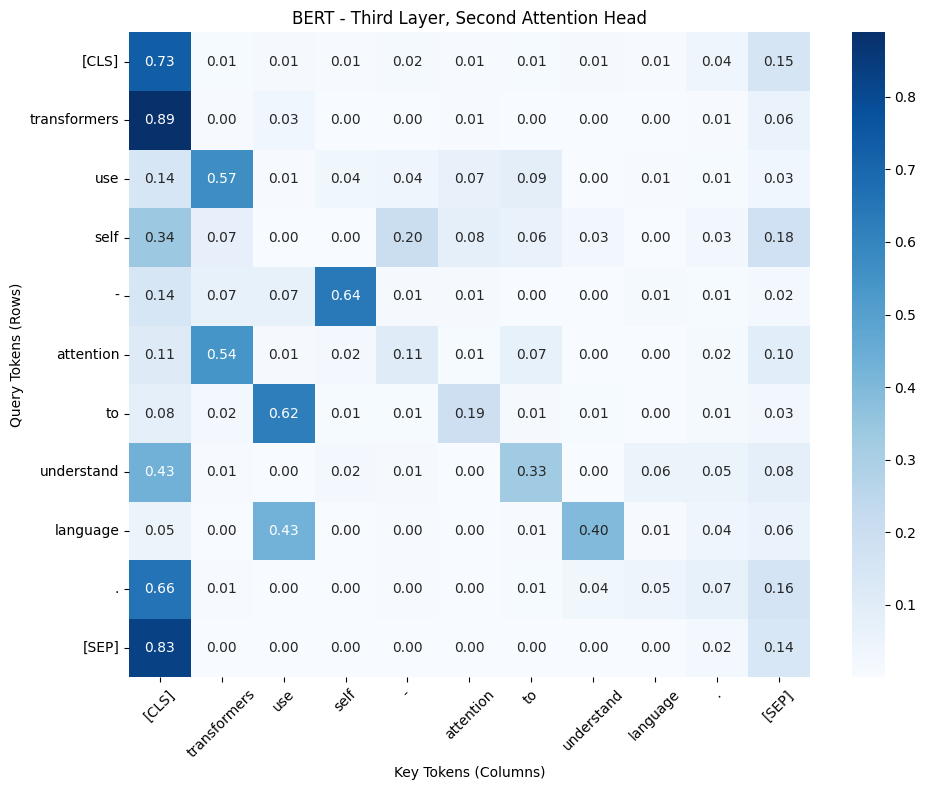

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.heatmap(
    attention.numpy(),
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="Blues",
    annot=True,
    fmt=".2f"
)

plt.title("BERT - Third Layer, Second Attention Head")
plt.xlabel("Key Tokens (Columns)")
plt.ylabel("Query Tokens (Rows)")
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()